In [ ]:
# STEP 1: Import Required Libraries

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.ensemble import RandomForestRegressor

from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

print("All libraries imported successfully!")

All libraries imported successfully!


In [2]:
# STEP 2: Upload and Load Dataset

from google.colab import files
import io

uploaded = files.upload()

filename = next(iter(uploaded))

df = pd.read_csv(io.BytesIO(uploaded[filename]))

print("Dataset loaded successfully!")

Saving weatherAUS.csv to weatherAUS.csv


NameError: name 'pd' is not defined

In [ ]:
# STEP 3: Understand the Dataset

print("FIRST FIVE ROWS")
display(df.head())

print("\nDATASET DIMENSIONS")
print("Number of rows:", df.shape[0])
print("Number of columns:", df.shape[1])

print("\nCOLUMN NAMES")
print(df.columns.tolist())

print("\nDATA TYPES")
df.info()

print("\nMISSING VALUES")
print(df.isnull().sum())

print("\nDUPLICATE RECORDS")
print(df.duplicated().sum())

print("\nSTATISTICAL SUMMARY")
display(df.describe(include="all").T)

FIRST FIVE ROWS


,Company,Product,TypeName,Inches,ScreenResolution,CPU_Company,CPU_Type,CPU_Frequency (GHz),RAM (GB),Memory,GPU_Company,GPU_Type,OpSys,Weight (kg),Price (Euro)
0,Apple,MacBook Pro,Ultrabook,13.3,IPS Panel Retina Display 2560x1600,Intel,Core i5,2.3,8,128GB SSD,Intel,Iris Plus Graphics 640,macOS,1.37,1339.69
1,Apple,Macbook Air,Ultrabook,13.3,1440x900,Intel,Core i5,1.8,8,128GB Flash Storage,Intel,HD Graphics 6000,macOS,1.34,898.94
2,HP,250 G6,Notebook,15.6,Full HD 1920x1080,Intel,Core i5 7200U,2.5,8,256GB SSD,Intel,HD Graphics 620,No OS,1.86,575.00
3,Apple,MacBook Pro,Ultrabook,15.4,IPS Panel Retina Display 2880x1800,Intel,Core i7,2.7,16,512GB SSD,AMD,Radeon Pro 455,macOS,1.83,2537.45
4,Apple,MacBook Pro,Ultrabook,13.3,IPS Panel Retina Display 2560x1600,Intel,Core i5,3.1,8,256GB SSD,Intel,Iris Plus Graphics 650,macOS,1.37,1803.60



DATASET DIMENSIONS
Number of rows: 1275
Number of columns: 15

COLUMN NAMES
['Company', 'Product', 'TypeName', 'Inches', 'ScreenResolution', 'CPU_Company', 'CPU_Type', 'CPU_Frequency (GHz)', 'RAM (GB)', 'Memory', 'GPU_Company', 'GPU_Type', 'OpSys', 'Weight (kg)', 'Price (Euro)']

DATA TYPES
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1275 entries, 0 to 1274
Data columns (total 15 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   Company              1275 non-null   object 
 1   Product              1275 non-null   object 
 2   TypeName             1275 non-null   object 
 3   Inches               1275 non-null   float64
 4   ScreenResolution     1275 non-null   object 
 5   CPU_Company          1275 non-null   object 
 6   CPU_Type             1275 non-null   object 
 7   CPU_Frequency (GHz)  1275 non-null   float64
 8   RAM (GB)             1275 non-null   int64  
 9   Memory               1275 non-null   object 


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
Company,1275,19,Dell,291,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Product,1275,618,XPS 13,30,NaN,NaN,NaN,NaN,NaN,NaN,NaN
TypeName,1275,6,Notebook,707,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Inches,1275.0,NaN,NaN,NaN,15.022902,1.42947,10.1,14.0,15.6,15.6,18.4
ScreenResolution,1275,40,Full HD 1920x1080,505,NaN,NaN,NaN,NaN,NaN,NaN,NaN
CPU_Company,1275,3,Intel,1214,NaN,NaN,NaN,NaN,NaN,NaN,NaN
CPU_Type,1275,93,Core i5 7200U,193,NaN,NaN,NaN,NaN,NaN,NaN,NaN
CPU_Frequency (GHz),1275.0,NaN,NaN,NaN,2.30298,0.503846,0.9,2.0,2.5,2.7,3.6
RAM (GB),1275.0,NaN,NaN,NaN,8.440784,5.097809,2.0,4.0,8.0,8.0,64.0
Memory,1275,39,256GB SSD,412,NaN,NaN,NaN,NaN,NaN,NaN,NaN


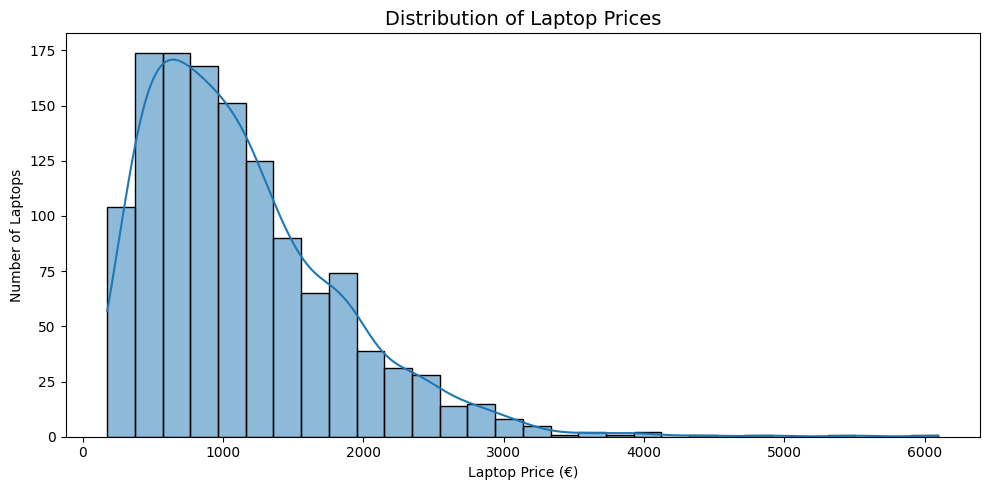

In [ ]:
# STEP 4: Laptop Price Distribution

plt.figure(figsize=(10, 5))

sns.histplot(
    data=df,
    x="Price (Euro)",
    bins=30,
    kde=True
)

plt.title("Distribution of Laptop Prices", fontsize=14)
plt.xlabel("Laptop Price (€)")
plt.ylabel("Number of Laptops")

plt.tight_layout()
plt.show()

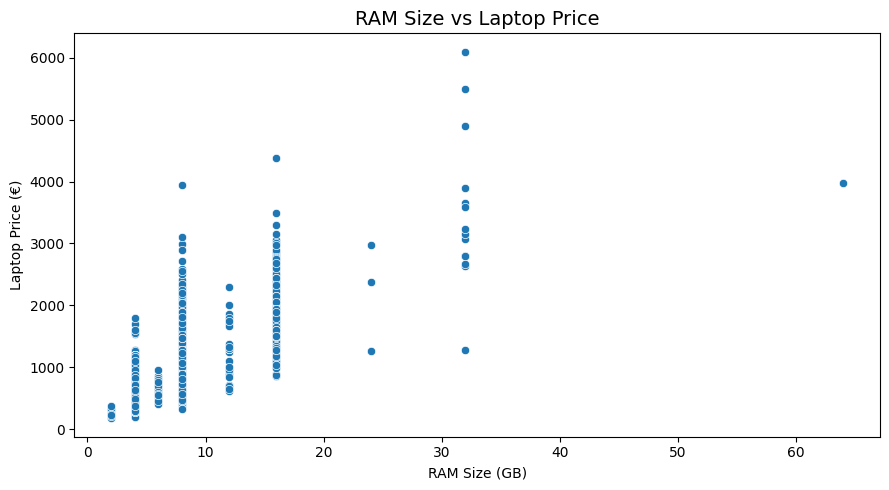

In [ ]:
# STEP 5: RAM vs Laptop Price

plt.figure(figsize=(9, 5))

sns.scatterplot(
    data=df,
    x="RAM (GB)",
    y="Price (Euro)"
)

plt.title("RAM Size vs Laptop Price", fontsize=14)
plt.xlabel("RAM Size (GB)")
plt.ylabel("Laptop Price (€)")

plt.tight_layout()
plt.show()

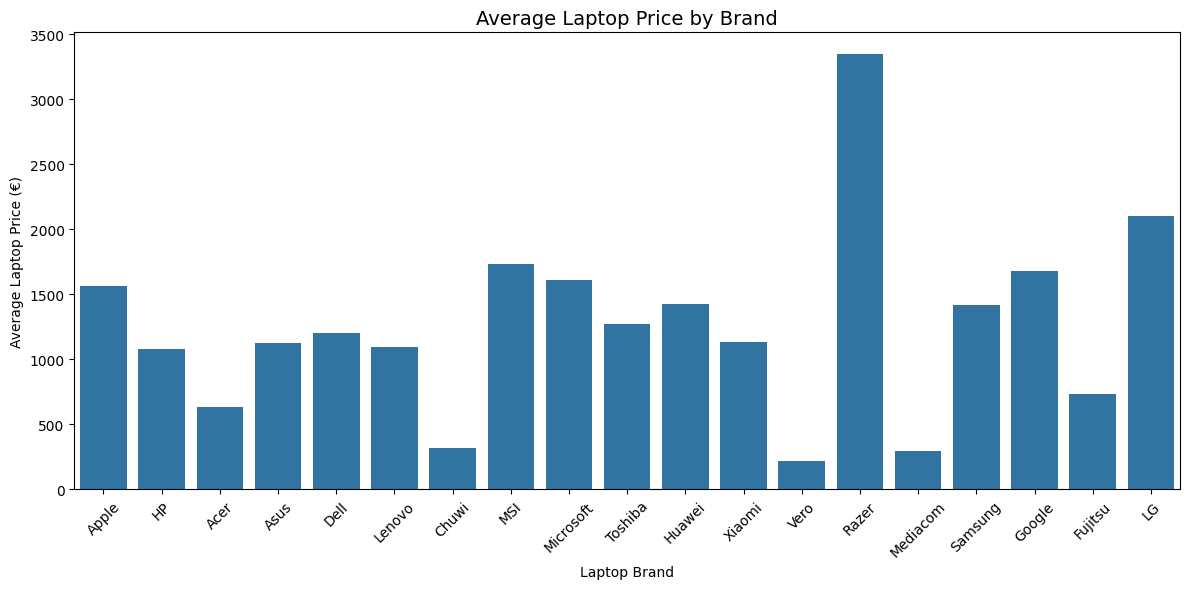

In [ ]:
# STEP 6: Average Price by Company

plt.figure(figsize=(12, 6))

sns.barplot(
    data=df,
    x="Company",
    y="Price (Euro)",
    errorbar=None
)

plt.title("Average Laptop Price by Brand", fontsize=14)
plt.xlabel("Laptop Brand")
plt.ylabel("Average Laptop Price (€)")

plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

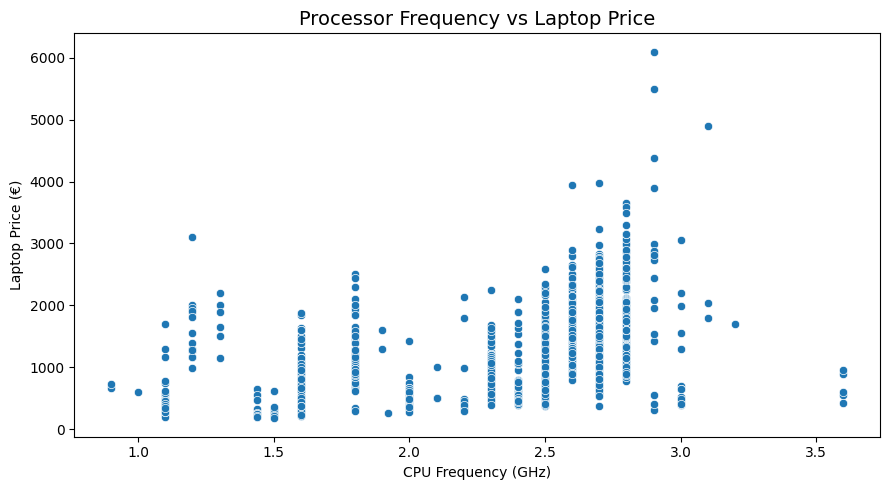

In [ ]:
# STEP 7: Processor Frequency vs Laptop Price

plt.figure(figsize=(9, 5))

sns.scatterplot(
    data=df,
    x="CPU_Frequency (GHz)",
    y="Price (Euro)"
)

plt.title("Processor Frequency vs Laptop Price", fontsize=14)
plt.xlabel("CPU Frequency (GHz)")
plt.ylabel("Laptop Price (€)")

plt.tight_layout()
plt.show()

In [ ]:
# STEP 7: Data Preprocessing

# Separate input features and target variable
X = df.drop("Price (Euro)", axis=1)
y = df["Price (Euro)"]

# Identify categorical and numerical columns
categorical_features = X.select_dtypes(
    include=["object", "category"]
).columns.tolist()

numerical_features = X.select_dtypes(
    include=["int64", "float64"]
).columns.tolist()

print("Categorical features:")
print(categorical_features)

print("\nNumerical features:")
print(numerical_features)

print("\nInput dataset shape:", X.shape)
print("Target dataset shape:", y.shape)

Categorical features:
['Company', 'Product', 'TypeName', 'ScreenResolution', 'CPU_Company', 'CPU_Type', 'Memory', 'GPU_Company', 'GPU_Type', 'OpSys']

Numerical features:
['Inches', 'CPU_Frequency (GHz)', 'RAM (GB)', 'Weight (kg)']

Input dataset shape: (1275, 14)
Target dataset shape: (1275,)


In [ ]:
# STEP 8: Train-Test Split

from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)

print("Training samples:", X_train.shape[0])
print("Testing samples:", X_test.shape[0])

print("\nTraining completed for data preparation!")

Training samples: 1020
Testing samples: 255

Training completed for data preparation!


In [ ]:
# STEP 9: Build and Train the Model

from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.ensemble import RandomForestRegressor

# Preprocessing for categorical features
categorical_transformer = Pipeline(
    steps=[
        (
            "imputer",
            SimpleImputer(strategy="most_frequent")
        ),
        (
            "encoder",
            OneHotEncoder(handle_unknown="ignore")
        )
    ]
)

# Preprocessing for numerical features
numerical_transformer = Pipeline(
    steps=[
        (
            "imputer",
            SimpleImputer(strategy="median")
        )
    ]
)

# Combine preprocessing steps
preprocessor = ColumnTransformer(
    transformers=[
        (
            "categorical",
            categorical_transformer,
            categorical_features
        ),
        (
            "numerical",
            numerical_transformer,
            numerical_features
        )
    ]
)

# Create the complete machine learning pipeline
model = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        (
            "regressor",
            RandomForestRegressor(
                n_estimators=200,
                random_state=42,
                n_jobs=-1
            )
        )
    ]
)

# Train the model
print("Training the Random Forest model...")

model.fit(X_train, y_train)

print("Model trained successfully!")

Training the Random Forest model...
Model trained successfully!


In [ ]:
# STEP 10: Evaluate the Model

import numpy as np

from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

# Predict prices for the test dataset
y_pred = model.predict(X_test)

# Calculate evaluation metrics
mae = mean_absolute_error(y_test, y_pred)

rmse = np.sqrt(
    mean_squared_error(y_test, y_pred)
)

r2 = r2_score(y_test, y_pred)

# Display results
print("=" * 45)
print("LAPTOP PRICE PREDICTION - MODEL RESULTS")
print("=" * 45)

print(f"R² Score: {r2:.4f}")
print(f"R² Percentage: {r2 * 100:.2f}%")

print(f"MAE: €{mae:.2f}")
print(f"RMSE: €{rmse:.2f}")

print("=" * 45)

LAPTOP PRICE PREDICTION - MODEL RESULTS
R² Score: 0.8757
R² Percentage: 87.57%
MAE: €168.14
RMSE: €248.42


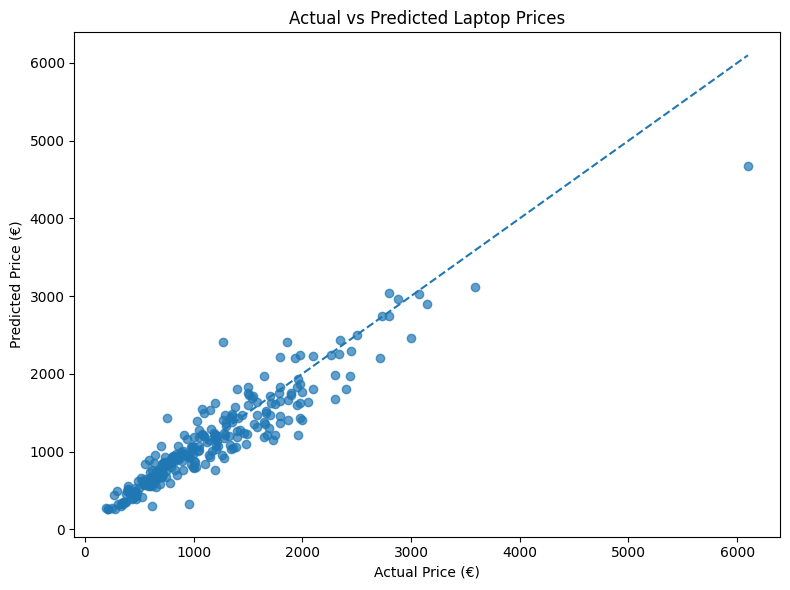

In [ ]:
# STEP 11: Actual vs Predicted Prices

plt.figure(figsize=(8, 6))

plt.scatter(
    y_test,
    y_pred,
    alpha=0.7
)

# Reference line for perfect predictions
min_price = min(y_test.min(), y_pred.min())
max_price = max(y_test.max(), y_pred.max())

plt.plot(
    [min_price, max_price],
    [min_price, max_price],
    linestyle="--"
)

plt.title("Actual vs Predicted Laptop Prices")
plt.xlabel("Actual Price (€)")
plt.ylabel("Predicted Price (€)")

plt.tight_layout()
plt.show()

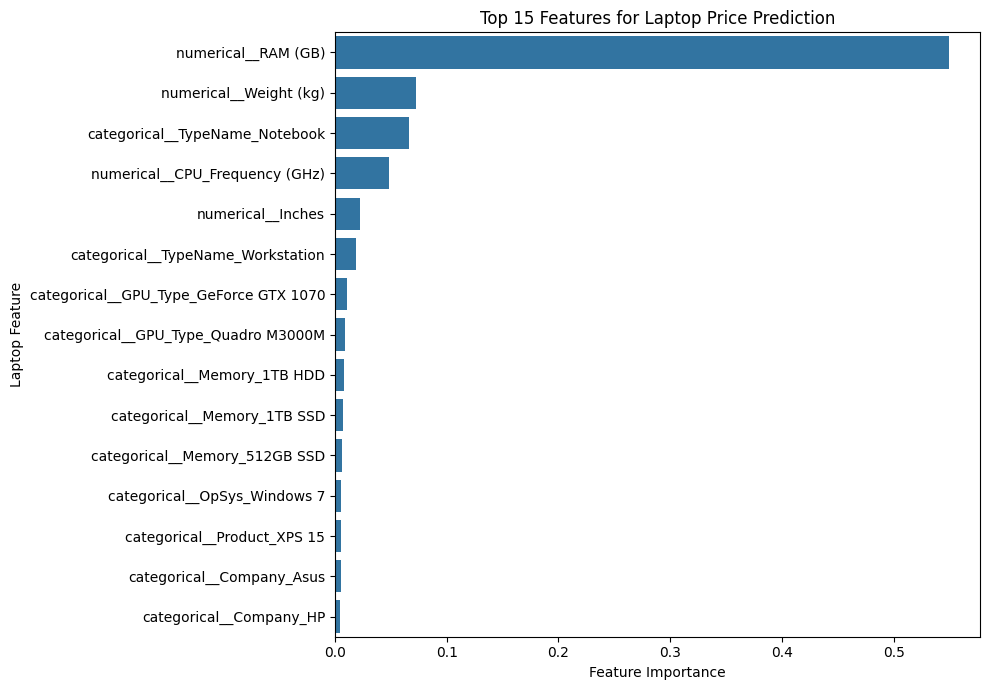

In [ ]:
# STEP 12: Feature Importance

# Get the fitted preprocessing component
fitted_preprocessor = model.named_steps["preprocessor"]

# Get the transformed feature names
feature_names = fitted_preprocessor.get_feature_names_out()

# Get Random Forest feature importance values
importances = model.named_steps["regressor"].feature_importances_

# Create a DataFrame
importance_df = pd.DataFrame({
    "Feature": feature_names,
    "Importance": importances
})

# Display the top 15 features
importance_df = importance_df.sort_values(
    by="Importance",
    ascending=False
).head(15)

plt.figure(figsize=(10, 7))

sns.barplot(
    data=importance_df,
    x="Importance",
    y="Feature"
)

plt.title("Top 15 Features for Laptop Price Prediction")
plt.xlabel("Feature Importance")
plt.ylabel("Laptop Feature")

plt.tight_layout()
plt.show()

In [ ]:
# Test a New Laptop Configuration

new_laptop = pd.DataFrame([{
    "Company": "Lenovo",
    "Product": "Legion Gaming Laptop",
    "TypeName": "Gaming",
    "Inches": 15.6,
    "ScreenResolution": "1920x1080",
    "CPU_Company": "Intel",
    "CPU_Type": "Core i7",
    "CPU_Frequency (GHz)": 3.2,
    "RAM (GB)": 16,
    "Memory": "512GB SSD",
    "GPU_Company": "Nvidia",
    "GPU_Type": "GeForce RTX 4060",
    "OpSys": "Windows 11",
    "Weight (kg)": 2.4
}])

# Predict the laptop price
predicted_price = model.predict(new_laptop)[0]

print("=" * 40)
print("LAPTOP PRICE PREDICTION")
print("=" * 40)
print(f"Predicted Price: €{predicted_price:.2f}")
print("=" * 40)

LAPTOP PRICE PREDICTION
Predicted Price: €2284.34


In [1]:
print("Model exists:", "model" in globals())
print("Dataset exists:", "df" in globals())
print("Training features exist:", "X_train" in globals())
print("Target exists:", "y" in globals())

Model exists: False
Dataset exists: False
Training features exist: False
Target exists: False


In [3]:
import pandas as pd
import io

In [4]:
from google.colab import files

uploaded = files.upload()

filename = next(iter(uploaded))

df = pd.read_csv(io.BytesIO(uploaded[filename]))

print("Dataset loaded successfully!")
print("Dataset shape:", df.shape)
df.head()

Saving laptop_price - dataset.csv to laptop_price - dataset.csv
Dataset loaded successfully!
Dataset shape: (1275, 15)


,Company,Product,TypeName,Inches,ScreenResolution,CPU_Company,CPU_Type,CPU_Frequency (GHz),RAM (GB),Memory,GPU_Company,GPU_Type,OpSys,Weight (kg),Price (Euro)
0,Apple,MacBook Pro,Ultrabook,13.3,IPS Panel Retina Display 2560x1600,Intel,Core i5,2.3,8,128GB SSD,Intel,Iris Plus Graphics 640,macOS,1.37,1339.69
1,Apple,Macbook Air,Ultrabook,13.3,1440x900,Intel,Core i5,1.8,8,128GB Flash Storage,Intel,HD Graphics 6000,macOS,1.34,898.94
2,HP,250 G6,Notebook,15.6,Full HD 1920x1080,Intel,Core i5 7200U,2.5,8,256GB SSD,Intel,HD Graphics 620,No OS,1.86,575.00
3,Apple,MacBook Pro,Ultrabook,15.4,IPS Panel Retina Display 2880x1800,Intel,Core i7,2.7,16,512GB SSD,AMD,Radeon Pro 455,macOS,1.83,2537.45
4,Apple,MacBook Pro,Ultrabook,13.3,IPS Panel Retina Display 2560x1600,Intel,Core i5,3.1,8,256GB SSD,Intel,Iris Plus Graphics 650,macOS,1.37,1803.60


In [5]:
print("Available datasets:")

for name, obj in globals().items():
    if isinstance(obj, pd.DataFrame):
        print(f"{name}: {obj.shape}")
        print(obj.head(3))

Available datasets:


RuntimeError: dictionary changed size during iteration

In [6]:
print("Available datasets:")

for name, obj in list(globals().items()):
    try:
        if isinstance(obj, pd.DataFrame):
            print(f"\nDataset variable: {name}")
            print(f"Shape: {obj.shape}")
            print(obj.head(3))
    except RuntimeError:
        continue

Available datasets:

Dataset variable: _
Shape: (5, 15)
  Company      Product   TypeName  Inches                    ScreenResolution  \
0   Apple  MacBook Pro  Ultrabook    13.3  IPS Panel Retina Display 2560x1600   
1   Apple  Macbook Air  Ultrabook    13.3                            1440x900   
2      HP       250 G6   Notebook    15.6                   Full HD 1920x1080   

  CPU_Company       CPU_Type  CPU_Frequency (GHz)  RAM (GB)  \
0       Intel        Core i5                  2.3         8   
1       Intel        Core i5                  1.8         8   
2       Intel  Core i5 7200U                  2.5         8   

                Memory GPU_Company                GPU_Type  OpSys  \
0            128GB SSD       Intel  Iris Plus Graphics 640  macOS   
1  128GB Flash Storage       Intel        HD Graphics 6000  macOS   
2            256GB SSD       Intel         HD Graphics 620  No OS   

   Weight (kg)  Price (Euro)  
0         1.37       1339.69  
1         1.34        898.9

In [7]:
print("Checking existing variables...\n")

for name in ["model", "pipeline", "best_model", "X_train", "y_train", "X", "y"]:
    if name in globals():
        obj = globals()[name]
        print(f"{name}: Available ({type(obj).__name__})")
    else:
        print(f"{name}: Not found")

Checking existing variables...

model: Not found
pipeline: Not found
best_model: Not found
X_train: Not found
y_train: Not found
X: Not found
y: Not found


In [9]:
# Import libraries
import pandas as pd
import numpy as np

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error

# Prepare dataset
df = df.copy()
df.columns = df.columns.str.strip()

# Remove rows with missing values
df = df.dropna()

# Separate features and target
X = df.drop(columns=["Price (Euro)"])
y = df["Price (Euro)"]

# Identify categorical and numerical columns
categorical_cols = X.select_dtypes(include=["object"]).columns.tolist()
numerical_cols = X.select_dtypes(exclude=["object"]).columns.tolist()

# Preprocess categorical features
preprocessor = ColumnTransformer(
    transformers=[
        ("categorical", OneHotEncoder(handle_unknown="ignore"), categorical_cols),
        ("numerical", "passthrough", numerical_cols)
    ]
)

# Create model pipeline
model = Pipeline([
    ("preprocessor", preprocessor),
    ("regressor", RandomForestRegressor(
        n_estimators=200,
        random_state=42,
        n_jobs=-1
    ))
])

# Split data into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

# Train model
model.fit(X_train, y_train)

# Evaluate model
y_pred = model.predict(X_test)

print("Model trained successfully!")
print(f"R² Score: {r2_score(y_test, y_pred):.4f}")
print(f"MAE: €{mean_absolute_error(y_test, y_pred):.2f}")
print(f"RMSE: €{np.sqrt(mean_squared_error(y_test, y_pred)):.2f}")

Model trained successfully!
R² Score: 0.8757
MAE: €168.14
RMSE: €248.42


In [10]:
!pip install -q gradio


In [ ]:
import gradio as gr
import pandas as pd

# Build dropdown choices from your dataset
companies = sorted(df["Company"].dropna().unique().tolist())
product_types = sorted(df["TypeName"].dropna().unique().tolist())
cpu_companies = sorted(df["CPU_Company"].dropna().unique().tolist())
cpu_types = sorted(df["CPU_Type"].dropna().unique().tolist())
gpu_companies = sorted(df["GPU_Company"].dropna().unique().tolist())
gpu_types = sorted(df["GPU_Type"].dropna().unique().tolist())
operating_systems = sorted(df["OpSys"].dropna().unique().tolist())
memories = sorted(df["Memory"].dropna().unique().tolist())
screen_resolutions = sorted(df["ScreenResolution"].dropna().unique().tolist())

# Prediction function
def predict_price(
    company, product, laptop_type, inches, screen_resolution,
    cpu_company, cpu_type, cpu_frequency, ram, memory,
    gpu_company, gpu_type, operating_system, weight
):
    laptop = pd.DataFrame([{
        "Company": company,
        "Product": product,
        "TypeName": laptop_type,
        "Inches": float(inches),
        "ScreenResolution": screen_resolution,
        "CPU_Company": cpu_company,
        "CPU_Type": cpu_type,
        "CPU_Frequency (GHz)": float(cpu_frequency),
        "RAM (GB)": int(ram),
        "Memory": memory,
        "GPU_Company": gpu_company,
        "GPU_Type": gpu_type,
        "OpSys": operating_system,
        "Weight (kg)": float(weight)
    }])

    prediction = model.predict(laptop)[0]
    return f"Estimated Laptop Price: €{prediction:,.2f}"

# Interface
with gr.Blocks(theme=gr.themes.Soft(), title="Laptop Price Predictor") as demo:
    gr.Markdown("# 💻 Laptop Price Prediction")
    gr.Markdown(
        "Enter the laptop specifications below to estimate its price in euros."
    )

    with gr.Row():
        company = gr.Dropdown(companies, label="Brand", value=companies[0])
        product = gr.Dropdown(
            sorted(df["Product"].dropna().unique().tolist()),
            label="Product", value=sorted(df["Product"].dropna().unique().tolist())[0]
        )
        laptop_type = gr.Dropdown(
            product_types, label="Laptop Type", value=product_types[0]
        )

    with gr.Row():
        inches = gr.Number(label="Screen Size (inches)", value=15.6)
        screen_resolution = gr.Dropdown(
            screen_resolutions, label="Screen Resolution",
            value=screen_resolutions[0]
        )
        weight = gr.Number(label="Weight (kg)", value=1.8)

    with gr.Row():
        cpu_company = gr.Dropdown(
            cpu_companies, label="CPU Manufacturer", value=cpu_companies[0]
        )
        cpu_type = gr.Dropdown(
            cpu_types, label="CPU Type", value=cpu_types[0]
        )
        cpu_frequency = gr.Number(
            label="CPU Frequency (GHz)", value=2.5
        )

    with gr.Row():
        ram = gr.Dropdown(
            sorted(df["RAM (GB)"].dropna().unique().tolist()),
            label="RAM (GB)", value=8
        )
        memory = gr.Dropdown(
            memories, label="Storage", value=memories[0]
        )

    with gr.Row():
        gpu_company = gr.Dropdown(
            gpu_companies, label="GPU Manufacturer", value=gpu_companies[0]
        )
        gpu_type = gr.Dropdown(
            gpu_types, label="GPU Type", value=gpu_types[0]
        )
        operating_system = gr.Dropdown(
            operating_systems, label="Operating System",
            value=operating_systems[0]
        )

    predict_button = gr.Button("Predict Laptop Price", variant="primary")
    result = gr.Textbox(label="Prediction Result", interactive=False)

    predict_button.click(
        fn=predict_price,
        inputs=[
            company, product, laptop_type, inches, screen_resolution,
            cpu_company, cpu_type, cpu_frequency, ram, memory,
            gpu_company, gpu_type, operating_system, weight
        ],
        outputs=result
    )

demo.launch(share=True, debug=True)

/tmp/ipykernel_509/1258401155.py:42: UserWarning: The parameters have been moved from the Blocks constructor to the launch() method in Gradio 6.0: theme. Please pass these parameters to launch() instead.
  with gr.Blocks(theme=gr.themes.Soft(), title="Laptop Price Predictor") as demo:


Colab notebook detected. This cell will run indefinitely so that you can see errors and logs. To turn off, set debug=False in launch().
* Running on public URL: https://bf7e20ea392571869a.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)
